# GEOG 6000 Final Project

### Load Libraries and Data

In [130]:
import numpy as np 
import geopandas as gpd
import pandas as pd 

In [131]:
jobs = gpd.read_file('Data/All_Jobs_TAZ_Projections_RTP_2023.shp')

households = gpd.read_file('Data/Household_TAZ_Projections_RTP_2023.shp')

type(jobs)

geopandas.geodataframe.GeoDataFrame

### Filter to only WFRC TAZ

In [132]:
jobs_wfrc = jobs[jobs['ModelArea'] == 'Wasatch Front Travel Demand Model']

household_wfrc = households[households['ModelArea'] == 'Wasatch Front Travel Demand Model']

type(jobs_wfrc)

geopandas.geodataframe.GeoDataFrame

### Create new DF with the Comm Score for each year 

In [133]:
# Define ONLY the numeric year columns for the math
year_cols = [f"YEAR{year}" for year in range(2019, 2051)]

# Set TAZID as the index on both GeoDataFrames
jobs_idx = jobs_wfrc.set_index("TAZID")
hh_idx = household_wfrc.set_index("TAZID")

# Run the 1.8-adjusted formula using ONLY year_cols
score_df = jobs_idx[year_cols] / (jobs_idx[year_cols] + 1.8 * hh_idx[year_cols])

# Turn score_df back into a GeoDataFrame by attaching the indexed geometry column
score_gdf = gpd.GeoDataFrame(score_df, geometry=jobs_idx["geometry"], crs=jobs_wfrc.crs)

### Checking for NA values

In [134]:
rows_with_nan = score_gdf.isna().any(axis=1).sum()
print(f"Rows with NaN: {rows_with_nan}")

Rows with NaN: 190


### Seperate between transiton NaN and only NaN

In [135]:
print(f"First check {score_gdf[year_cols].isna().any(axis=1).sum()}")

print(f"second check {score_gdf[year_cols].isna().all(axis=1).sum()}")


First check 190
second check 96


### Map out the 94 transition taz
96 taz stay 0 from 2019 till 2050 which we can drop

figure out what to do with the other 94 taz


Transitional TAZ count: 94


<Axes: xlabel='Easting [Meter]', ylabel='Northing [Meter]'>

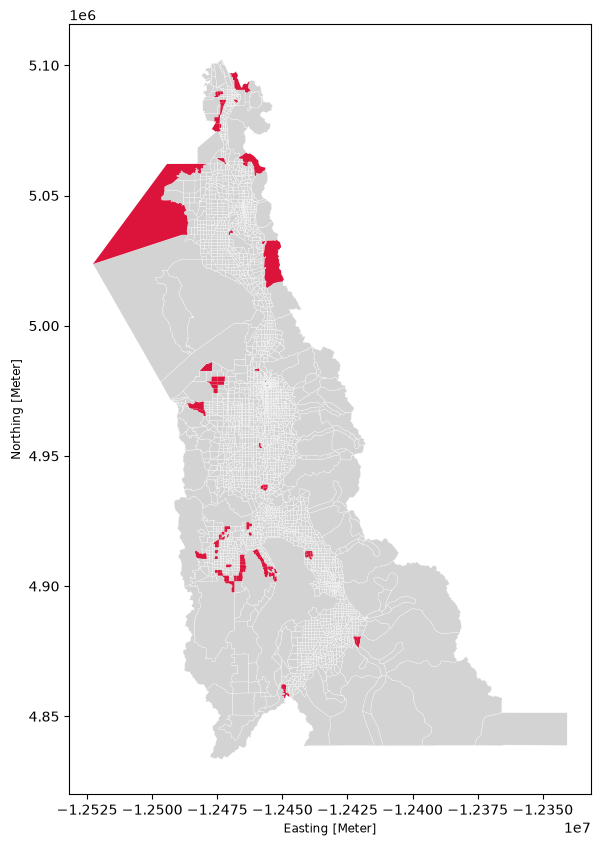

In [136]:
# Store two boolean checks on year_cols
has_some_na = score_gdf[year_cols].isna().any(axis=1)
is_all_na = score_gdf[year_cols].isna().all(axis=1)

# Keep rows where has_some_na is True AND is_all_na is NOT True (~)
transitional_gdf = score_gdf[has_some_na & ~ is_all_na]
print(f"Transitional TAZ count: {len(transitional_gdf)}")

# Plot
ax = score_gdf.plot(color="lightgrey", edgecolor="white", linewidth=0.2, figsize=(8, 10))
transitional_gdf.plot(ax=ax, color="crimson")

### Drop taz that stay NAN

In [137]:
score_gdf = score_gdf.dropna(subset = year_cols,how ="all")

# Checks for NaN
rows_with_nan = score_gdf.isna().any(axis=1).sum()
print(f"Rows with NaN: {rows_with_nan}")

Rows with NaN: 94


### Backfill rows that transition

In [140]:
score_gdf[year_cols] = score_gdf[year_cols].bfill(axis = 1)

# Checks for NaN
rows_with_nan = score_gdf.isna().any(axis=1).sum()
print(f"Rows with NaN: {rows_with_nan}")

Rows with NaN: 1


There is still one more row that was not caught. It only has the last few years where it did not stay at 1 fill it with 1. 

In [141]:
# Inspect that row
score_gdf[score_gdf.isna().any(axis=1)]

,YEAR2019,YEAR2020,YEAR2021,YEAR2022,YEAR2023,YEAR2024,YEAR2025,YEAR2026,YEAR2027,YEAR2028,...,YEAR2042,YEAR2043,YEAR2044,YEAR2045,YEAR2046,YEAR2047,YEAR2048,YEAR2049,YEAR2050,geometry
TAZID,,,,,,,,,,,,,,,,,,,,,
5763,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,"POLYGON ((-12470498.288 4901901.271, -12470394..."


### Fill NA with 1 for last row

In [143]:
score_gdf[year_cols] = score_gdf[year_cols].fillna(1)

rows_with_nan = score_gdf.isna().any(axis=1).sum()
print(f"Rows with NaN: {rows_with_nan}")


Rows with NaN: 0


score_gdf.head

In [144]:
type(score_gdf)

geopandas.geodataframe.GeoDataFrame